In [16]:
import numpy as np
import matplotlib.pyplot as plt

points = {
    'a': np.array([0.6, 1.9]),
    'b': np.array([1.8, 1.6]),
    'c': np.array([2.7, 2.0]),
    'd': np.array([3.0, 2.1]),
    'e': np.array([3.0, 2.6]),
    'f': np.array([3.1, 4.5]),
    'g': np.array([3.8, 0.6]),
    'h': np.array([4.2, 2.7])
}
labels = list(points.keys())
coords = np.array([points[l] for l in labels])

def cosine_sim(a, b):
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    if norm_a == 0 or norm_b == 0:
        return 0.0
    return np.dot(a, b) / (norm_a * norm_b)

def cosine_dist(a, b):
    return 1 - cosine_sim(a, b)

In [17]:
def kmeans(points, init_centers, max_iter=10):
    centers = {name: points[name].copy() for name in init_centers}
    history = []
    for it in range(max_iter):
        clusters = {c: [] for c in centers}
        for pt_name, pt in points.items():
            best_c = max(centers.keys(), key=lambda c: cosine_sim(pt, centers[c]))
            clusters[best_c].append(pt_name)
        history.append((clusters, centers.copy()))
        new_centers = {}
        for c, pts in clusters.items():
            if pts:
                new_centers[c] = np.mean([points[p] for p in pts], axis=0)
            else:
                new_centers[c] = centers[c]
        if all(np.allclose(centers[c], new_centers[c]) for c in centers):
            break
        centers = new_centers
    return clusters, centers, history

init_centers = ['f', 'g']
final_clusters, final_centers, kmeans_history = kmeans(points, init_centers)

for c, pts in final_clusters.items():
    print(f"Кластер {c}: {sorted(pts)}")
print("Центры:")
for c, cent in final_centers.items():
    print(f"  {c}: {cent}")

Кластер f: ['a', 'b', 'c', 'd', 'e', 'f', 'h']
Кластер g: ['g']
Центры:
  f: [2.62857143 2.48571429]
  g: [3.8 0.6]


In [18]:
def plot_kmeans_steps(points, history):
    n_steps = len(history)
    cols = min(4, n_steps)
    rows = (n_steps + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*4))
    axes = axes.flatten()
    for step, (clusters, centers) in enumerate(history):
        ax = axes[step]
        col_map = {'f': 'red', 'g': 'blue'}
        for c_name, pts in clusters.items():
            col = col_map[c_name]
            for pt in pts:
                coord = points[pt]
                ax.scatter(*coord, color=col, s=80, edgecolors='black')
                ax.text(coord[0]+0.05, coord[1]+0.05, pt, fontsize=9)
        for c_name, cent in centers.items():
            ax.scatter(*cent, marker='X', color=col_map[c_name], s=150, edgecolors='black', linewidth=2)
        ax.set_title(f"Итерация {step+1}")
        ax.grid(True, alpha=0.3)
    for j in range(n_steps, len(axes)):
        axes[j].axis('off')
    plt.suptitle("K-means: изменение центроидов", fontsize=14)
    plt.tight_layout()
    plt.show()

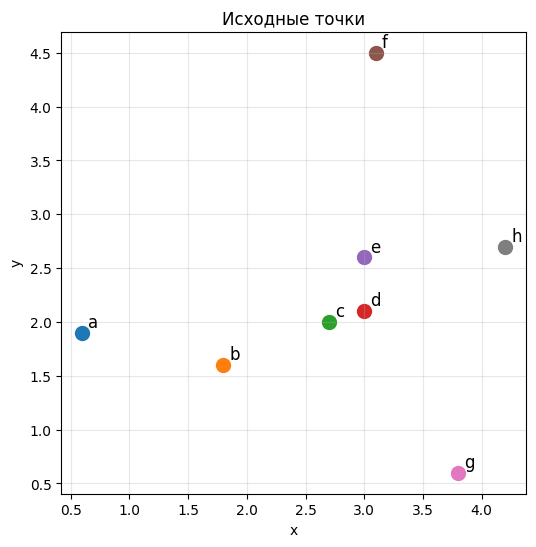

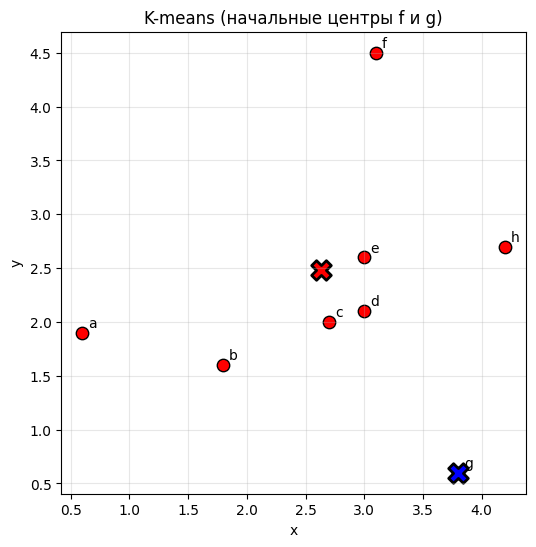

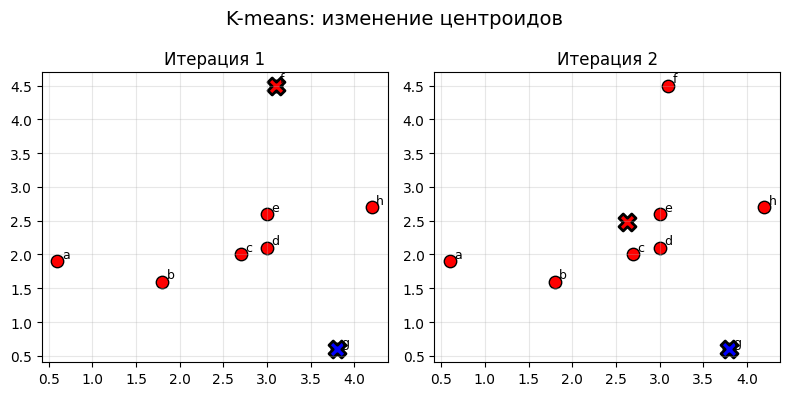

In [19]:
plt.figure(figsize=(6, 6))
for lbl, coord in points.items():
    plt.scatter(*coord, s=100)
    plt.text(coord[0]+0.05, coord[1]+0.05, lbl, fontsize=12)
plt.title("Исходные точки")
plt.xlabel("x"); plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

# 2. Результат K-means
plt.figure(figsize=(6, 6))
colors_kmeans = {'f':'red', 'g':'blue'}
for c_name, pts in final_clusters.items():
    for pt in pts:
        coord = points[pt]
        plt.scatter(*coord, color=colors_kmeans[c_name], s=80, edgecolors='black')
        plt.text(coord[0]+0.05, coord[1]+0.05, pt, fontsize=10)
for c_name, cent in final_centers.items():
    plt.scatter(*cent, marker='X', color=colors_kmeans[c_name], s=200, edgecolors='black', linewidth=2)
plt.title("K-means (начальные центры f и g)")
plt.xlabel("x"); plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

plot_kmeans_steps(points, kmeans_history)

In [20]:
def agglomerative(points, linkage='single'):
    n = len(points)
    point_list = list(points.values())
    clusters = [{'id': i, 'items': {i}} for i in range(n)]
    sim_matrix = np.zeros((n, n))
    for i in range(n):
        for j in range(i+1, n):
            s = cosine_sim(point_list[i], point_list[j])
            sim_matrix[i, j] = s
            sim_matrix[j, i] = s

    merges = []
    step_history = []
    next_id = n

    while len(clusters) > 1:
        best_sim = -1.0
        best_i = best_j = None
        for i in range(len(clusters)):
            for j in range(i+1, len(clusters)):
                if linkage == 'single':
                    sim = max(sim_matrix[a, b] for a in clusters[i]['items'] for b in clusters[j]['items'])
                else:
                    sim = min(sim_matrix[a, b] for a in clusters[i]['items'] for b in clusters[j]['items'])
                if sim > best_sim:
                    best_sim = sim
                    best_i, best_j = i, j
        new_items = clusters[best_i]['items'] | clusters[best_j]['items']
        new_cluster = {'id': next_id, 'items': new_items}
        merges.append((clusters[best_i]['id'], clusters[best_j]['id'], best_sim, len(new_items)))

        state_clusters = [c['items'] for c in clusters]
        step_history.append((state_clusters, best_sim, best_i, best_j))

        clusters = [c for idx, c in enumerate(clusters) if idx not in (best_i, best_j)]
        clusters.append(new_cluster)
        next_id += 1
    return merges, step_history

merges_single, steps_single = agglomerative(points, linkage='single')
merges_complete, steps_complete = agglomerative(points, linkage='complete')

print("\nSINGLE-LINK")
for m in merges_single:
    print(f"Объединение {m[0]} и {m[1]}, сходство = {m[2]:.4f}, размер = {m[3]}")
print("\nCOMPLETE-LINK")
for m in merges_complete:
    print(f"Объединение {m[0]} и {m[1]}, сходство = {m[2]:.4f}, размер = {m[3]}")


SINGLE-LINK
Объединение 1 и 4, сходство = 0.9999, размер = 2
Объединение 2 и 3, сходство = 0.9996, размер = 2
Объединение 7 и 9, сходство = 0.9992, размер = 3
Объединение 8 и 10, сходство = 0.9971, размер = 5
Объединение 5 и 11, сходство = 0.9711, размер = 6
Объединение 0 и 12, сходство = 0.9561, размер = 7
Объединение 6 и 13, сходство = 0.9152, размер = 8

COMPLETE-LINK
Объединение 1 и 4, сходство = 0.9999, размер = 2
Объединение 2 и 3, сходство = 0.9996, размер = 2
Объединение 7 и 9, сходство = 0.9978, размер = 3
Объединение 8 и 10, сходство = 0.9880, размер = 5
Объединение 0 и 5, сходство = 0.9561, размер = 2
Объединение 6 и 11, сходство = 0.8419, размер = 6
Объединение 12 и 13, сходство = 0.4462, размер = 8


In [21]:
def plot_dendrogram(merges, labels, title):
    n = len(labels)
    nodes = {}
    for i in range(n):
        nodes[i] = {'children': [], 'height': 0.0, 'leaf': True, 'leaf_idx': i}
    for left, right, sim, size in merges:
        new_id = max(nodes.keys()) + 1
        nodes[new_id] = {
            'children': [left, right],
            'height': 1 - sim,
            'leaf': False
        }
    all_children = set()
    for node in nodes.values():
        if not node['leaf']:
            all_children.update(node['children'])
    root = max(set(nodes.keys()) - all_children)

    order = []
    def traverse(node_id):
        if nodes[node_id]['leaf']:
            order.append(nodes[node_id]['leaf_idx'])
        else:
            for ch in nodes[node_id]['children']:
                traverse(ch)
    traverse(root)

    fig, ax = plt.subplots(figsize=(10, 5))
    leaf_x = {idx: i for i, idx in enumerate(order)}
    def draw(node_id):
        node = nodes[node_id]
        if node['leaf']:
            x = leaf_x[node['leaf_idx']]
            y = 0.0
            ax.plot([x, x], [0, node['height']], 'k-', lw=1)
            return x, node['height']
        else:
            left_id, right_id = node['children']
            x_left, h_left = draw(left_id)
            x_right, h_right = draw(right_id)
            x_mid = (x_left + x_right) / 2
            y_mid = node['height']
            ax.plot([x_left, x_right], [y_mid, y_mid], 'k-', lw=2)
            ax.plot([x_left, x_left], [h_left, y_mid], 'k-', lw=1)
            ax.plot([x_right, x_right], [h_right, y_mid], 'k-', lw=1)
            return x_mid, y_mid
    draw(root)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([labels[i] for i in order])
    ax.set_ylabel("Косинусное расстояние")
    ax.set_title(title)
    ax.grid(True, axis='y', alpha=0.3)
    return fig

def show_agglomerative_steps(points, steps, method_name, max_cols=4):
    n_steps = len(steps)
    cols = min(max_cols, n_steps+1)
    rows = (n_steps + cols) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*4))
    axes = axes.flatten()
    ax = axes[0]
    for lbl, coord in points.items():
        ax.scatter(*coord, s=80)
        ax.text(coord[0]+0.05, coord[1]+0.05, lbl, fontsize=10)
    ax.set_title("Шаг 0: каждая точка отдельно")
    ax.grid(True, alpha=0.3)
    for i, (clusters, sim, idx1, idx2) in enumerate(steps, start=1):
        if i >= len(axes):
            break
        ax = axes[i]
        colors = plt.cm.tab10(np.linspace(0, 1, len(clusters)))
        for cl, col in zip(clusters, colors):
            for pt_idx in cl:
                pt_name = labels[pt_idx]
                coord = points[pt_name]
                ax.scatter(*coord, color=col, s=80)
                ax.text(coord[0]+0.05, coord[1]+0.05, pt_name, fontsize=9)
        ax.set_title(f"Шаг {i}: сходство = {sim:.3f}")
        ax.grid(True, alpha=0.3)
    for j in range(i+1, len(axes)):
        axes[j].axis('off')
    plt.suptitle(method_name, fontsize=14)
    plt.tight_layout()
    plt.show()

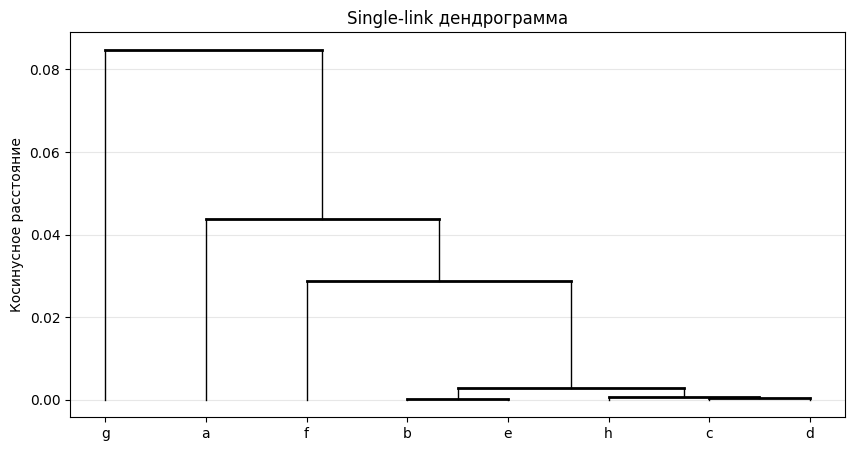

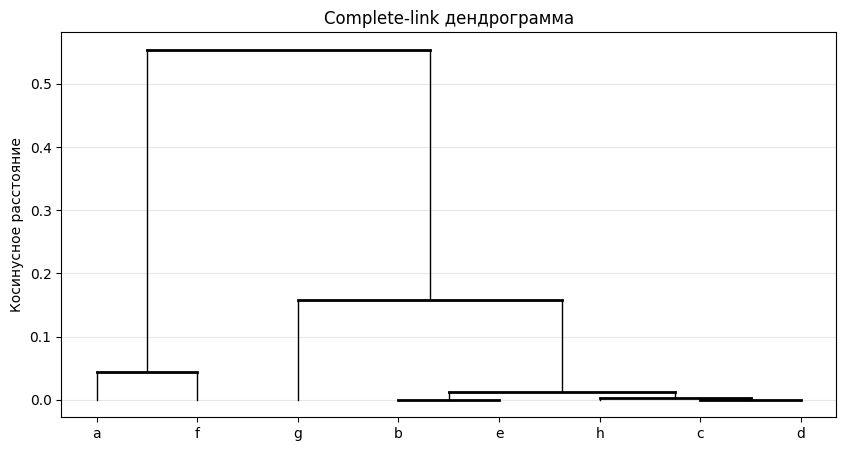

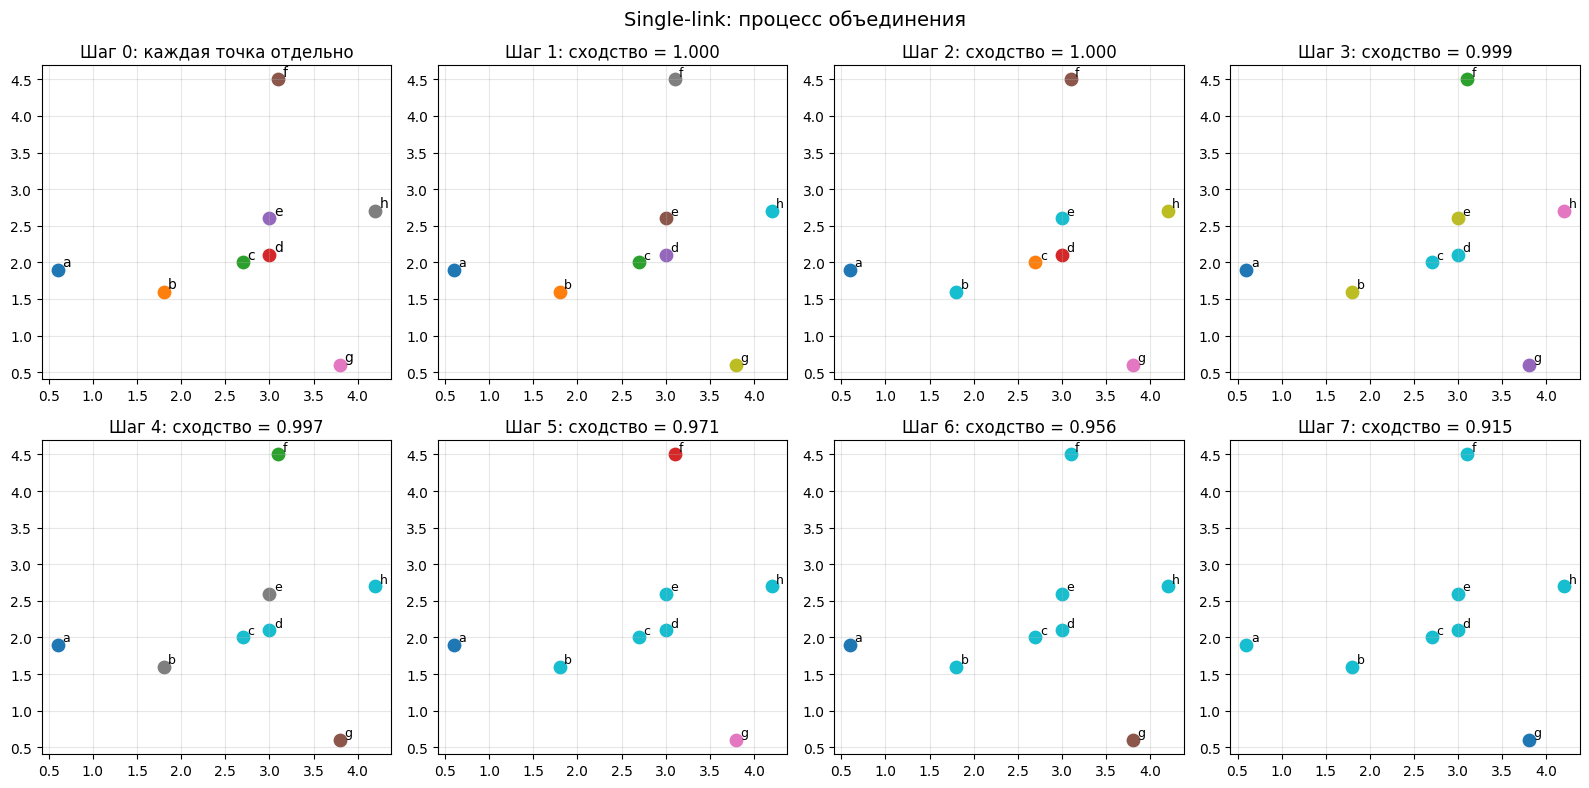

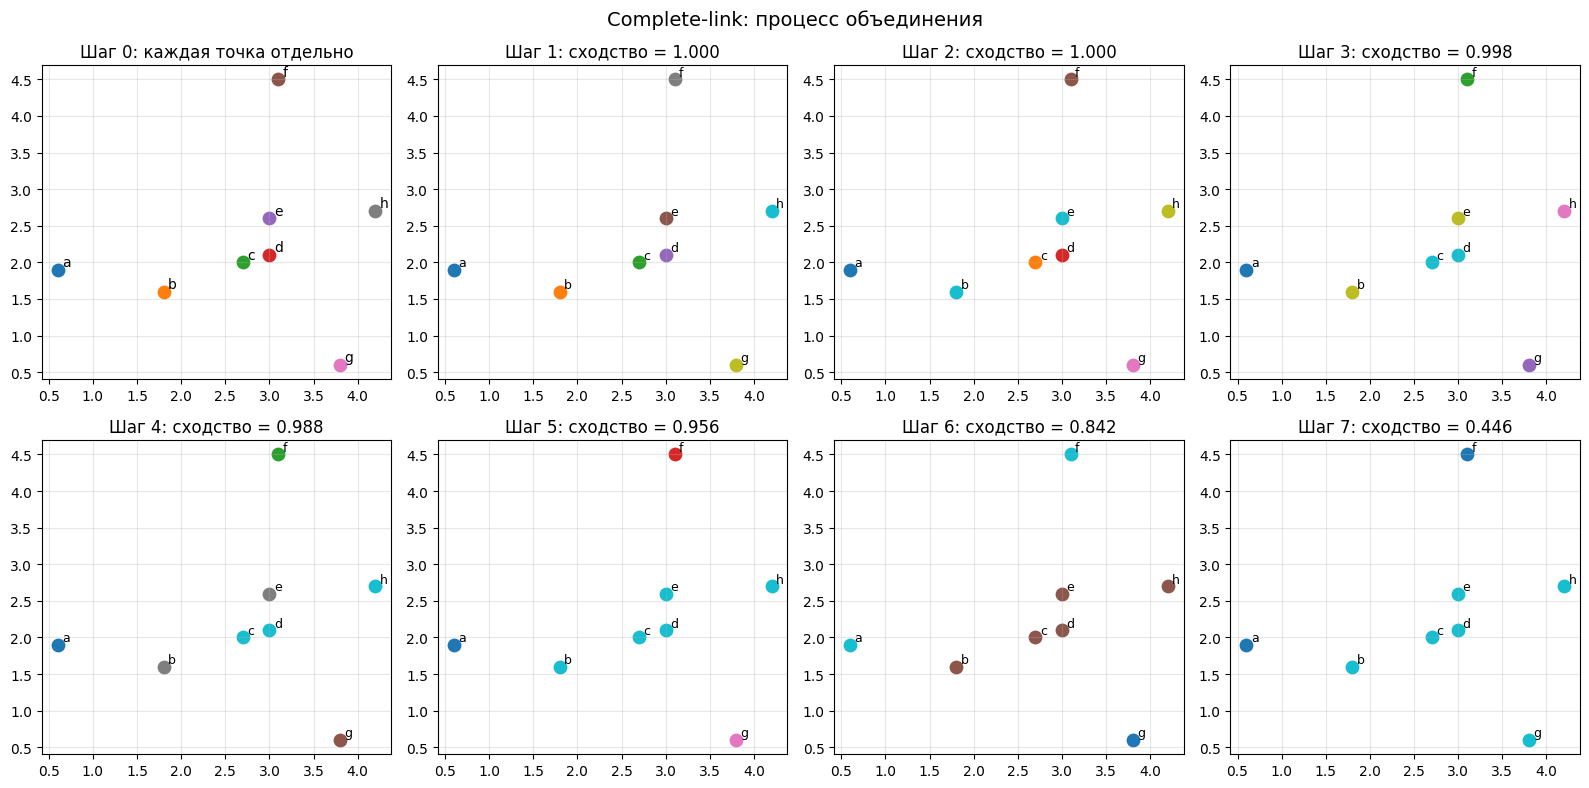

In [22]:
plot_dendrogram(merges_single, labels, "Single‑link дендрограмма")
plot_dendrogram(merges_complete, labels, "Complete‑link дендрограмма")
plt.show()

show_agglomerative_steps(points, steps_single, "Single‑link: процесс объединения")
show_agglomerative_steps(points, steps_complete, "Complete‑link: процесс объединения")